**INITIAL TED TALKS RECOMMENDATION**

**Activity 1- Dataset summary**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [5]:
from pathlib import Path

df = pd.read_csv(Path(r"C:\Users\bhava\Downloads\ted_talks.csv\2020-05-01\ted_talks_es.csv"))


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 3921
Number of columns: 19


In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nColumn data types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Column names:
['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript']

Column data types:
talk_id             int64
title              object
speaker_1          object
all_speakers       object
occupations        object
about_speakers     object
views               int64
recorded_date      object
published_date     object
event              object
native_lang        object
available_lang     object
comments          float64
duration            int64
topics             object
related_talks      object
url                object
description        object
transcript         object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3921 entries, 0 to 3920
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          -------

In [8]:
print("Numerical column statistics:")
display(df.describe())

print("Statistics for all columns:")
display(df.describe(include="all").T)

Numerical column statistics:


,talk_id,views,comments,duration
count,3921.000000,3.921000e+03,3306.000000,3921.000000
mean,11717.001530,2.181844e+06,163.724743,720.147156
std,16701.411669,3.479143e+06,270.151216,347.903102
min,1.000000,0.000000e+00,0.000000,60.000000
25%,1231.000000,9.031590e+05,39.000000,390.000000
50%,2293.000000,1.398294e+06,90.000000,736.000000
75%,22799.000000,2.164966e+06,189.750000,974.000000
max,62782.000000,6.505253e+07,6449.000000,3922.000000


Statistics for all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
talk_id,3921.0,NaN,NaN,NaN,11717.00153,16701.411669,1.0,1231.0,2293.0,22799.0,62782.0
title,3921,3921,Al Gore sobre cómo evitar la crisis climática,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speaker_1,3921,3210,Alex Gendler,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
all_speakers,3918,3238,{0: 'Alex Gendler'},33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupations,3409,2010,{0: ['writer']},53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
about_speakers,3423,2911,{0: 'Juan Enriquez thinks and writes about the...,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
views,3921.0,NaN,NaN,NaN,2181843.833971,3479143.302759,0.0,903159.0,1398294.0,2164966.0,65052534.0
recorded_date,3920,1311,2017-04-24,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_date,3921,2942,2017-09-07,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event,3921,449,TED-Ed,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
# Look for possible talk identifiers
possible_ids = ["talk_id", "id", "video_id", "url"]
id_col = next(
    (col for col in possible_ids if col in df.columns),
    None
)

if id_col:
    print("Identifier column:", id_col)
    print("Unique talks:", df[id_col].nunique())
else:
    print("No standard talk identifier found.")
    print("Inspect the columns to identify a suitable unique identifier.")

Identifier column: talk_id
Unique talks: 3822


**Activity 2-Missing values and Duplicates**

In [16]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_report.sort_values(
    by="Missing Percentage", ascending=False
))

,Missing Count,Missing Percentage
comments,557,14.57
occupations,500,13.08
about_speakers,493,12.90
description,2,0.05
all_speakers,2,0.05
recorded_date,1,0.03
talk_id,0,0.00
url,0,0.00
related_talks,0,0.00
topics,0,0.00


In [17]:
text_cols = df.select_dtypes(include=["object", "string"]).columns

empty_report = {}

for col in text_cols:
    empty_report[col] = df[col].apply(
        lambda x: isinstance(x, str) and x.strip() == ""
    ).sum()

empty_report = pd.Series(empty_report, name="Empty Strings")
display(empty_report.to_frame())

,Empty Strings
title,0
speaker_1,0
all_speakers,0
occupations,0
about_speakers,0
recorded_date,0
published_date,0
event,0
native_lang,0
available_lang,0


In [18]:
print("Number of duplicate rows:", df.duplicated().sum())

duplicate_rows = df[df.duplicated(keep=False)]
display(duplicate_rows.head(10))

Number of duplicate rows: 0


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript


In [19]:
if id_col:
    repeated_ids = df[df.duplicated(subset=[id_col], keep=False)]

    print("Rows with repeated identifiers:", len(repeated_ids))
    display(repeated_ids.sort_values(id_col).head(10))
else:
    print("Repeated identifier analysis skipped: no identifier found.")

Rows with repeated identifiers: 0


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript


In [20]:
important_fields = [
    "title", "description", "tags",
    "transcript", "url"
]

for col in important_fields:
    if col in df.columns:
        missing = df[col].isna().sum()
        empty = df[col].apply(
            lambda x: isinstance(x, str) and x.strip() == ""
        ).sum()

        print(f"{col}: missing={missing}, empty={empty}")
    else:
        print(f"{col}: column not available")

title: missing=0, empty=0
description: missing=2, empty=0
tags: column not available
transcript: missing=0, empty=0
url: missing=0, empty=0


**Activity 3-Text Analysis**

In [21]:
print("Available text-related columns:")

for col in df.columns:
    if any(word in col.lower() for word in
           ["title", "description", "transcript", "tag", "url"]):
        print(col)

Available text-related columns:
title
url
description
transcript


In [22]:
def get_text_stats(data, column):
    if column not in data.columns:
        print(f"Column '{column}' is not available.")
        return None

    text = data[column].fillna("").astype(str)

    result = pd.DataFrame({
        "text_length": text.str.len(),
        "word_count": text.str.split().str.len()
    })

    return result


for col in ["description", "transcript", "title"]:
    stats = get_text_stats(df, col)

    if stats is not None:
        print(f"\nStatistics for {col}:")
        display(stats.describe().round(2))

        print("Empty entries:", (stats["text_length"] == 0).sum())
        print("Entries shorter than 10 characters:",
              (stats["text_length"] < 10).sum())


Statistics for description:


,text_length,word_count
count,3822.00,3822.00
mean,136.68,3.90
std,57.31,4.02
min,0.00,0.00
25%,97.00,1.00
50%,124.00,3.00
75%,163.00,5.00
max,688.00,65.00


Empty entries: 2
Entries shorter than 10 characters: 2

Statistics for transcript:


,text_length,word_count
count,3822.00,3822.00
mean,3323.60,286.78
std,1734.81,143.61
min,9.00,2.00
25%,1753.50,159.00
50%,3306.00,288.00
75%,4536.25,387.00
max,17357.00,1559.00


Empty entries: 0
Entries shorter than 10 characters: 1

Statistics for title:


,text_length,word_count
count,3822.00,3822.00
mean,17.64,1.70
std,7.60,1.13
min,2.00,1.00
25%,12.00,1.00
50%,16.00,1.00
75%,22.00,2.00
max,68.00,11.00


Empty entries: 0
Entries shorter than 10 characters: 444


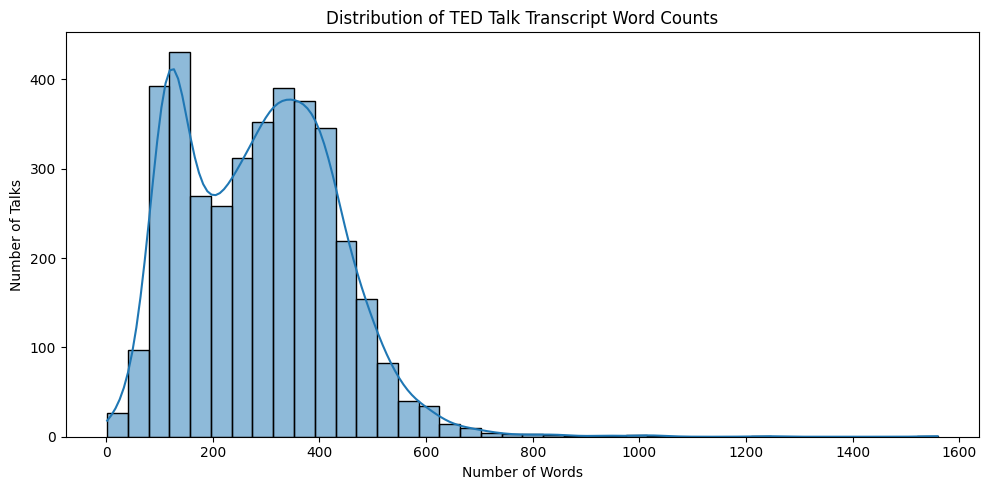

In [23]:
if "transcript" in df.columns:
    transcript_lengths = (
        df["transcript"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    plt.figure(figsize=(10, 5))
    sns.histplot(transcript_lengths, bins=40, kde=True)
    plt.title("Distribution of TED Talk Transcript Word Counts")
    plt.xlabel("Number of Words")
    plt.ylabel("Number of Talks")
    plt.tight_layout()
    plt.show()
else:
    print("Transcript column is not available.")

**Activity 4- Tag and topic analysis**

Top 15 TED Talk tags:


topics
'science'          794
'technology'       597
'culture'          510
'global issues'    495
'society'          435
'design'           424
'social change'    418
'health'           349
'humanity'         336
'innovation'       330
'technology']      327
'TED-Ed'           322
['TEDx'            321
'animation'        320
'history'          314
Name: count, dtype: int64

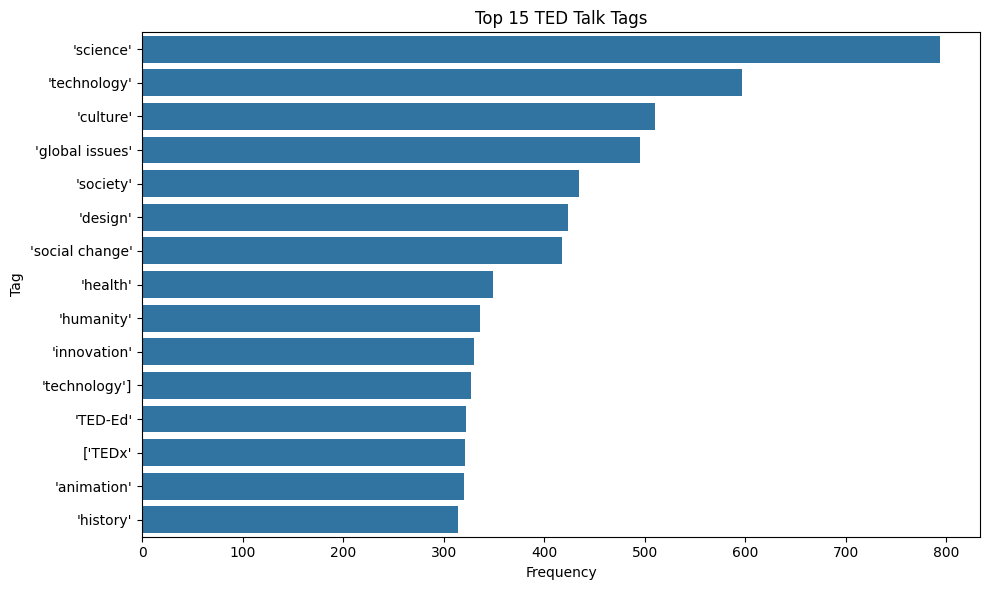

In [26]:
tag_column = next(
    (col for col in ["tags", "tag", "topics", "topic"]
     if col in df.columns),
    None
)

if tag_column:
    tags = df[tag_column].dropna().astype(str)

    # Supports common comma-separated or list-like tag formats.
    # Inspect your data first if the format differs.
    tag_list = tags.str.split(r",|;|\|")

    all_tags = tag_list.explode().str.strip()
    all_tags = all_tags[all_tags != ""]

    tag_frequency = all_tags.value_counts()

    print("Top 15 TED Talk tags:")
    display(tag_frequency.head(15))

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=tag_frequency.head(15).values,
        y=tag_frequency.head(15).index
    )
    plt.title("Top 15 TED Talk Tags")
    plt.xlabel("Frequency")
    plt.ylabel("Tag")
    plt.tight_layout()
    plt.show()
else:
    print("No tag or topic column is available.")

**Activity 5-Additional Data Analysis**

In [27]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns:", numeric_cols)
display(df[numeric_cols].describe().T)

Numerical columns: ['talk_id', 'views', 'comments', 'duration']


,count,mean,std,min,25%,50%,75%,max
talk_id,3822.0,1.102684e+04,1.603927e+04,1.0,1205.25,2239.5,20367.25,62347.0
views,3822.0,2.215144e+06,3.507967e+06,0.0,929323.25,1414582.0,2181901.25,65051830.0
comments,3265.0,1.653908e+02,2.713608e+02,1.0,41.00,92.0,191.00,6449.0
duration,3822.0,7.196531e+02,3.458761e+02,60.0,388.00,736.0,976.00,3608.0


In [28]:
for col in df.columns:
    if any(term in col.lower() for term in
           ["duration", "view", "rating", "count"]):
        print(f"\nColumn: {col}")
        print("Data type:", df[col].dtype)
        display(df[col].describe())

        if pd.api.types.is_numeric_dtype(df[col]):
            print("Zero values:", (df[col] == 0).sum())
            print("Negative values:", (df[col] < 0).sum())


Column: views
Data type: int64


count    3.822000e+03
mean     2.215144e+06
std      3.507967e+06
min      0.000000e+00
25%      9.293232e+05
50%      1.414582e+06
75%      2.181901e+06
max      6.505183e+07
Name: views, dtype: float64

Zero values: 1
Negative values: 0

Column: duration
Data type: int64


count    3822.000000
mean      719.653061
std       345.876061
min        60.000000
25%       388.000000
50%       736.000000
75%       976.000000
max      3608.000000
Name: duration, dtype: float64

Zero values: 0
Negative values: 0


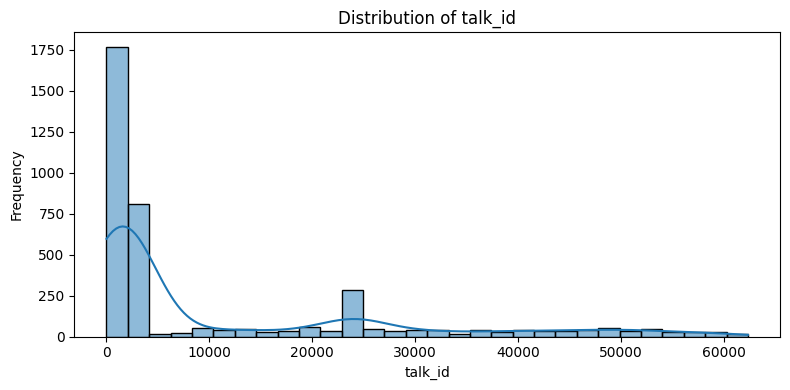

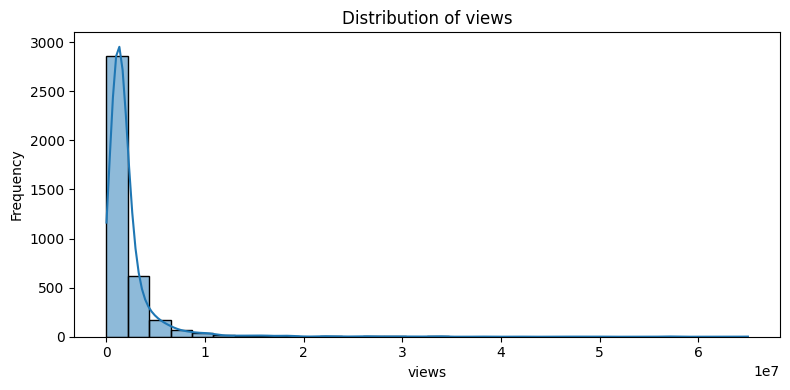

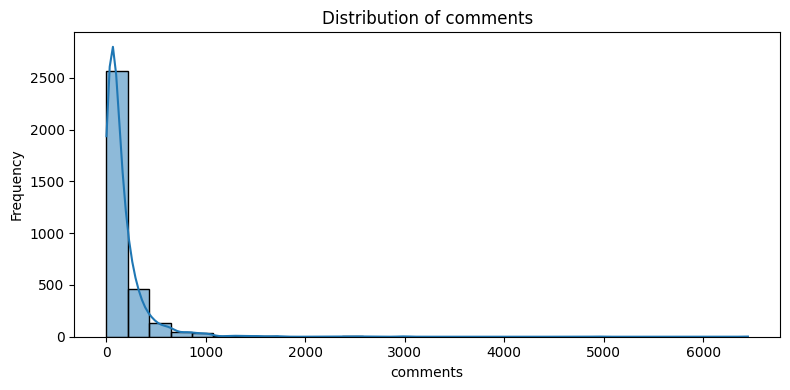

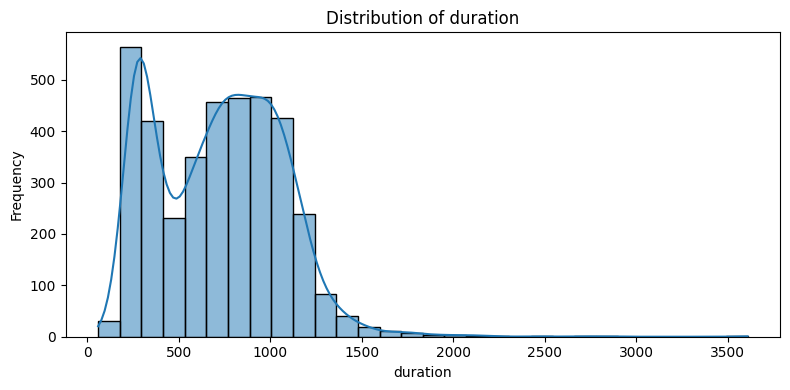

In [29]:
for col in numeric_cols:
    values = df[col].dropna()

    if values.empty:
        continue

    plt.figure(figsize=(8, 4))
    sns.histplot(values, bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

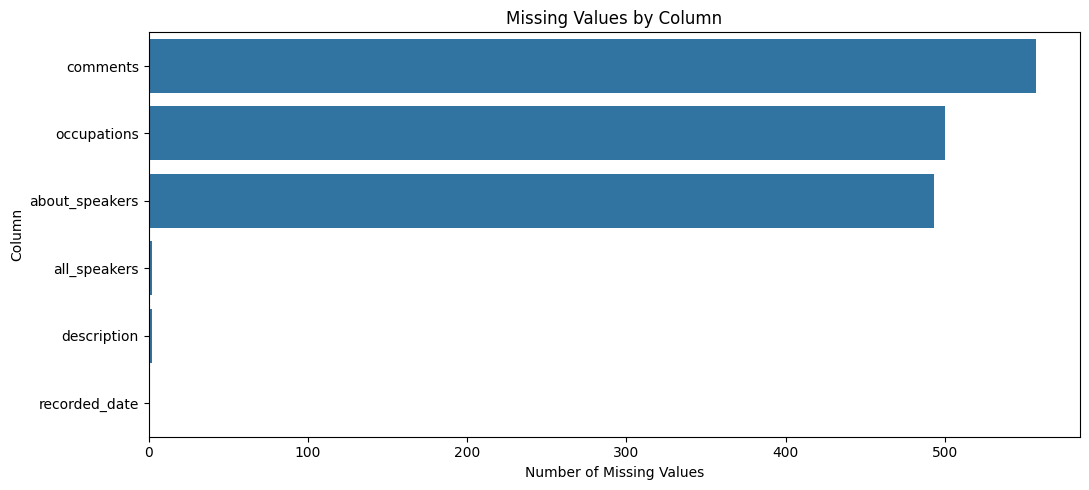

In [30]:
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

if not missing_counts.empty:
    plt.figure(figsize=(11, 5))

    sns.barplot(
        x=missing_counts.values,
        y=missing_counts.index
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No null values found in the dataset.")